# 05 — FP16-storage compression of the winner (v1.2)
**Goal:** shrink `models/winner/model.onnx` **without losing score**, and record the evidence.

**Why (after notebook 04, v1.1):**
- The winner is **xlmr-base FP32 ONNX, 1.06 GB**. INT8 dynamic quantization cut it to 266 MB but lost
  **10.3 pt** of val macro-F1, so notebook 04 (correctly) kept FP32.
- Guidelines §3: scoring is **correctness**, schema compliance and robustness, so accuracy can't be traded for size.
  Deliverable 3: the container must run **offline**, so the model has to live inside the Docker image. A 1 GB
  file makes the image, the GitHub repo (Git LFS quota) and every deploy heavy.

**Method: FP16 storage, FP32 compute** (`src/tfml/compress.py`)
- Every large float32 weight is stored as float16 (2 bytes instead of 4), followed by a `Cast` back to float32.
- ONNX Runtime folds those casts when it loads the model, so inference still runs in **float32** with the same kernels
  and speed. The only change is that each weight is rounded to float16 (about 3 significant digits).
- No retraining, no torch, CPU only (a few minutes).

**Acceptance (decided before running):** on the **same** splits as notebook 04 (val_test = held-out 50% of validation,
seed 42), with the **same** decode settings from `inference_config.json`:
- category agreement with FP32 on the full validation set ≥ 99.5%
- |Δ| ≤ 0.005 for category macro-F1, secondary F1, urgency F1 and ECE on val_test

If any check fails, FP32 stays the shipped model and this notebook only reports the result.

**Runtime:** CPU is fine. Run notebook 04 first (it writes `models/winner/`).

In [1]:
# --- Environment setup (Colab or local) -------------------------------------------------
import os, sys, json, shutil, subprocess, time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/TensorForge/training")   # upload the `training/` folder here
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements-colab.txt")], check=True)
else:
    ROOT = Path.cwd().resolve().parent                  # training/notebooks -> training/

sys.path.insert(0, str(ROOT / "src"))
from tfml.paths import Paths
P = Paths(ROOT)
print("ROOT:", P.root)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tfml import data as D, metrics as M
from tfml import compress as C
from tfml.rules import decode_arrays, check_consistency
from tfml.onnx_runtime import OnnxTicketClassifier, benchmark

STAGE = P.models / "staging"; STAGE.mkdir(parents=True, exist_ok=True)
FP32_MASTER = STAGE / "winner_fp32.onnx"      # untouched FP32 copy (source of every conversion)
FP16_PATH = STAGE / "winner_fp16w.onnx"

Mounted at /content/drive
ROOT: /content/drive/MyDrive/TensorForge/training


## 5.1 Load the exported winner and keep an FP32 master copy
Re-running this notebook is safe: the conversion always starts from `models/staging/winner_fp32.onnx`, never from an
already-compressed `models/winner/model.onnx`.

In [2]:
cfg = json.loads((P.winner / "inference_config.json").read_text())
winner_onnx = P.winner / cfg["onnx_file"]
if cfg["precision"] == "fp32":
    # Fresh notebook-04 export: verify it, then (re)create the master copy from it.
    sha = C.file_sha256(winner_onnx)
    assert sha == cfg["model_sha256"], "models/winner/model.onnx does not match inference_config.json (re-run notebook 04)"
    if not FP32_MASTER.exists() or C.file_sha256(FP32_MASTER) != sha:
        shutil.copy2(winner_onnx, FP32_MASTER)
    fp32_version, fp32_sha = cfg["model_version"], sha
else:
    # Already compressed by an earlier run of this notebook: use the recorded FP32 source.
    src = cfg["compression"]
    assert FP32_MASTER.exists() and C.file_sha256(FP32_MASTER) == src["source_fp32_sha256"], \
        "FP32 master missing/changed: re-run notebook 04 to re-export the FP32 winner"
    fp32_version, fp32_sha = src["source_model_version"], src["source_fp32_sha256"]

DECODE = cfg["decode"]
print("winner:", cfg["model_key"], "| precision:", cfg["precision"], "| FP32 version:", fp32_version)
print(f"FP32 master: {FP32_MASTER.stat().st_size / 2**20:.0f} MB | decode settings: {DECODE}")

winner: xlmr-base | precision: fp32 | FP32 version: v1.1-ff6ac27e5faa
FP32 master: 1059 MB | decode settings: {'temperature': 1.5954600883547825, 'urgency_threshold': 0.425, 'secondary_threshold': 0.4, 'review_threshold': 0.7}


## 5.2 Convert: FP16 storage, FP32 compute

In [3]:
t0 = time.perf_counter()
conv = C.fp16_storage(FP32_MASTER, FP16_PATH)
print(f"{conv['src_mb']:.0f} MB -> {conv['dst_mb']:.0f} MB in {time.perf_counter() - t0:.0f} s")
print(f"converted {conv['converted_tensors']} weight tensors ({conv['converted_fraction']:.2%} of all float weights)")
print(f"largest rounding error per weight: abs {conv['max_abs_weight_error']:.2e}, rel {conv['max_rel_weight_error']:.2e}")

1059 MB -> 530 MB in 22 s
converted 89 weight tensors (99.97% of all float weights)
largest rounding error per weight: abs 8.82e-04, rel 4.88e-04


## 5.3 Score check on the same splits as notebook 04
Both models run exactly like the API: one ticket per forward pass, same tokenizer, same decode settings.

In [4]:
splits = D.load_processed(P)
val_df, dev_df = splits["val"], splits["dev"]
# Identical to notebook 04 cell 18: 50/50 stratified by category, seed 42.
cal_idx, test_idx = train_test_split(np.arange(len(val_df)), test_size=0.5, random_state=42, stratify=val_df["category"])
cal_idx, test_idx = np.sort(cal_idx), np.sort(test_idx)
val_test_df = val_df.iloc[test_idx].reset_index(drop=True)

COLS = ["ticket_id", "channel", "subject", "text"]
tickets = val_df[COLS].to_dict(orient="records")
logits = {}
for name, path in [("fp32", FP32_MASTER), ("fp16w", FP16_PATH)]:
    clf = OnnxTicketClassifier(P.winner, onnx_file=str(path), n_threads=4)
    t0 = time.perf_counter()
    logits[name] = clf.logits(tickets, batch_size=1)
    print(f"{name}: {len(tickets)} tickets in {time.perf_counter() - t0:.0f} s")
    del clf

def sub(lg, idx):
    return {k: v[idx] for k, v in lg.items()}

# Raw agreement on the full validation set
dec_full = {n: decode_arrays(lg["category"], lg["secondary"], lg["urgency"], DECODE) for n, lg in logits.items()}
agree = {
    "max |Δ category logit|": float(np.abs(logits["fp32"]["category"] - logits["fp16w"]["category"]).max()),
    "max |Δ confidence|": float(np.abs(dec_full["fp32"]["confidence"] - dec_full["fp16w"]["confidence"]).max()),
}
for key in ["category", "secondary", "is_urgent", "needs_human_review"]:
    agree[f"{key} agreement"] = float((dec_full["fp32"][key] == dec_full["fp16w"][key]).mean())
print(pd.Series(agree).to_string())

# Metrics with the shipped decode settings: val_test (headline) and full val
m = {}
for name, lg in logits.items():
    m[(name, "val_test")] = M.compute_metrics(val_test_df, decode_arrays(*(sub(lg, test_idx)[k] for k in ("category", "secondary", "urgency")), DECODE))
    m[(name, "val_full")] = M.compute_metrics(val_df, dec_full[name])
cmp = pd.DataFrame(m)
for split in ("val_test", "val_full"):
    cmp[("Δ fp16w-fp32", split)] = cmp[("fp16w", split)] - cmp[("fp32", split)]
cmp = cmp.loc[["category_acc", "category_macro_f1", "secondary_acc", "secondary_f1", "urgency_f1", "exact_match", "ece"]]
print(cmp.round(4).to_string())

fp32: 800 tickets in 290 s
fp16w: 800 tickets in 275 s
max |Δ category logit|          0.019704
max |Δ confidence|              0.003405
category agreement              1.000000
secondary agreement             1.000000
is_urgent agreement             1.000000
needs_human_review agreement    1.000000
                      fp32             fp16w          Δ fp16w-fp32         
                  val_test val_full val_test val_full     val_test val_full
category_acc        0.8025   0.8088   0.8025   0.8088        0.000      0.0
category_macro_f1   0.8057   0.8136   0.8057   0.8136        0.000      0.0
secondary_acc       0.9825   0.9812   0.9825   0.9812        0.000      0.0
secondary_f1        0.9014   0.8980   0.9014   0.8980        0.000      0.0
urgency_f1          0.9429   0.9565   0.9429   0.9565        0.000      0.0
exact_match         0.7900   0.7962   0.7900   0.7962        0.000      0.0
ece                 0.0615   0.0524   0.0635   0.0524        0.002     -0.0


In [5]:
TOL = 0.005
d = lambda k: abs(m[("fp16w", "val_test")][k] - m[("fp32", "val_test")][k])
acceptance = pd.DataFrame([
    ("category agreement (full val) ≥ 99.5%", agree["category agreement"], agree["category agreement"] >= 0.995),
    ("|Δ category macro-F1| ≤ 0.005 (val_test)", d("category_macro_f1"), d("category_macro_f1") <= TOL),
    ("|Δ secondary F1| ≤ 0.005 (val_test)", d("secondary_f1"), d("secondary_f1") <= TOL),
    ("|Δ urgency F1| ≤ 0.005 (val_test)", d("urgency_f1"), d("urgency_f1") <= TOL),
    ("|Δ ECE| ≤ 0.005 (val_test)", d("ece"), d("ece") <= TOL),
], columns=["check", "value", "pass"])
USE_FP16 = bool(acceptance["pass"].all())
print(acceptance.to_string(index=False))
print("\nDECISION:", "ship FP16-storage model" if USE_FP16 else "keep FP32 (a check failed)")

                                   check    value  pass
   category agreement (full val) ≥ 99.5% 1.000000  True
|Δ category macro-F1| ≤ 0.005 (val_test) 0.000000  True
     |Δ secondary F1| ≤ 0.005 (val_test) 0.000000  True
       |Δ urgency F1| ≤ 0.005 (val_test) 0.000000  True
              |Δ ECE| ≤ 0.005 (val_test) 0.001989  True

DECISION: ship FP16-storage model


## 5.4 Size vs. score across all exported artifacts
Default decode (T = 1, argmax) on the full validation set, so the numbers line up with notebook 04's
quantization table (`metrics.json → onnx_quantization`).

                  size_mb  category_macro_f1  secondary_f1  urgency_f1
artifact                                                              
FP32            1058.6925             0.8136        0.8904      0.9434
FP16 storage     529.6274             0.8136        0.8904      0.9434
INT8 (dynamic)   265.6761             0.7110        0.6822      0.9054


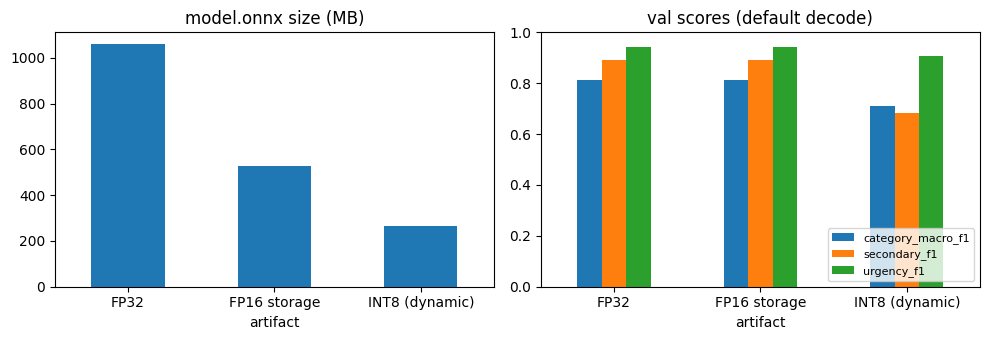

In [6]:
metrics_json = json.loads((P.winner / "metrics.json").read_text())
quant = metrics_json.get("onnx_quantization", {})
int8_file = STAGE / "model_int8.onnx"
rows = []
for name, lg, size in [("FP32", logits["fp32"], FP32_MASTER.stat().st_size), ("FP16 storage", logits["fp16w"], FP16_PATH.stat().st_size)]:
    mm = M.compute_metrics(val_df, decode_arrays(lg["category"], lg["secondary"], lg["urgency"]))
    rows.append({"artifact": name, "size_mb": size / 2**20, **{k: mm[k] for k in ("category_macro_f1", "secondary_f1", "urgency_f1")}})
if "int8_val" in quant:
    rows.append({"artifact": "INT8 (dynamic)", "size_mb": int8_file.stat().st_size / 2**20 if int8_file.exists() else np.nan,
                 **{k: quant["int8_val"][k] for k in ("category_macro_f1", "secondary_f1", "urgency_f1")}})
tradeoff = pd.DataFrame(rows).set_index("artifact")
print(tradeoff.round(4).to_string())
tradeoff.to_csv(P.results / "compression.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
tradeoff["size_mb"].plot.bar(ax=axes[0], title="model.onnx size (MB)", rot=0)
tradeoff[["category_macro_f1", "secondary_f1", "urgency_f1"]].plot.bar(ax=axes[1], title="val scores (default decode)", rot=0)
axes[1].set_ylim(0, 1); axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(P.figures / "5_1_compression_tradeoff.png", dpi=120, bbox_inches="tight"); plt.show()

## 5.5 Package (only if every acceptance check passed)
`model_version` changes because the file changes: `v1.2-<sha256[:12]>`. The FP32 source version and hash are kept
in `inference_config.json → compression`, so the shipped file can always be traced back to the notebook-04 export.

In [7]:
if USE_FP16:
    shutil.copy2(FP16_PATH, P.winner / "model.onnx")
    sha = C.file_sha256(P.winner / "model.onnx")
    cfg.update({
        "onnx_file": "model.onnx",
        "precision": "fp16-storage (fp32 compute)",
        "model_sha256": sha,
        "version_prefix": "v1.2",
        "model_version": f"v1.2-{sha[:12]}",
        "compression": {"method": "fp16 storage of float32 weights + Cast to float32 (tfml.compress.fp16_storage)",
                        "source_model_version": fp32_version, "source_fp32_sha256": fp32_sha,
                        "notebook": "05_fp16_compression.ipynb"},
    })
    (P.winner / "inference_config.json").write_text(json.dumps(cfg, indent=2, ensure_ascii=False))
    metrics_json.update({
        "val": m[("fp16w", "val_test")],            # headline = the shipped artifact on held-out val_test
        "val_fp32_before_compression": m[("fp32", "val_test")],
        "compression": {"conversion": conv, "agreement_full_val": agree,
                        "acceptance": acceptance.astype(str).to_dict(orient="records"),
                        "tradeoff": tradeoff.reset_index().to_dict(orient="records")},
        "artifact": "fp16-storage",
    })
    (P.winner / "metrics.json").write_text(json.dumps(metrics_json, indent=2, default=str))
    print("shipped:", cfg["model_version"], f"({(P.winner / 'model.onnx').stat().st_size / 2**20:.0f} MB)")
else:
    print("kept FP32:", cfg["model_version"])

shipped: v1.2-558395869056 (530 MB)


## 5.6 Final checks on the packaged artifact (exactly what the API will load)

In [8]:
import psutil, gc
gc.collect()
rss0 = psutil.Process().memory_info().rss
clf = OnnxTicketClassifier(P.winner, n_threads=2)
rss_model = (psutil.Process().memory_info().rss - rss0) / 2**20
assert clf.model_version == json.loads((P.winner / "inference_config.json").read_text())["model_version"]

shuffled = val_df.sample(frac=1, random_state=0)[COLS].to_dict(orient="records")
bench = benchmark(clf, shuffled, n_single=50)
preds = clf.predict(tickets)
again = clf.predict(tickets[:100])
deterministic = preds[:100] == again
batch_invariant = [clf.predict([t])[0] for t in tickets[:30]] == preds[:30]
violations = check_consistency(preds)
shipped = "fp16w" if USE_FP16 else "fp32"
from tfml.labels import CATEGORIES
agreement = float((pd.DataFrame(preds).category.values == np.array(CATEGORIES)[dec_full[shipped]["category"]]).mean())
print({k: round(v, 3) for k, v in bench.items()}, f"| model RSS ≈ {rss_model:.0f} MB")
print("version:", clf.model_version, "| deterministic:", deterministic, "| batch-invariant:", batch_invariant,
      "| contract violations:", len(violations), "| agreement with 5.3:", round(agreement, 4))
assert deterministic and batch_invariant and not violations and agreement >= 0.995

metrics_json = json.loads((P.winner / "metrics.json").read_text())
metrics_json.update({"latency_onnx_2threads": bench, "model_rss_mb": rss_model,
                     "package_mb": sum(f.stat().st_size for f in P.winner.rglob("*") if f.is_file()) / 2**20})
(P.winner / "metrics.json").write_text(json.dumps(metrics_json, indent=2, default=str))
print(f"package size: {metrics_json['package_mb']:.0f} MB")

{'p50_ms': 328.587, 'p95_ms': 699.289, 'p99_ms': 777.264, 'mean_ms': 372.875, 'batch100_s': 29.715} | model RSS ≈ 887 MB
version: v1.2-558395869056 | deterministic: True | batch-invariant: True | contract violations: 0 | agreement with 5.3: 1.0
package size: 546 MB
